<a href="https://colab.research.google.com/github/bonobobit/qff2026/blob/main/string_matching.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

A quantum algorithm for string matching.
Implementazione dell'algoritmo descritto in
Niroula, P., Nam, Y. A quantum algorithm for string matching. npj Quantum Inf 7, 37 (2021). https://doi.org/10.1038/s41534-021-00369-3

In [2]:
%pip install qiskit pylatexenc numpy qiskit_aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 35.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 91.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 76.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [qiskit_aer]


In [7]:
from qiskit import QuantumRegister, QuantumCircuit
import numpy as np
from qiskit.circuit.library import QFTGate
from qiskit_aer import AerSimulator

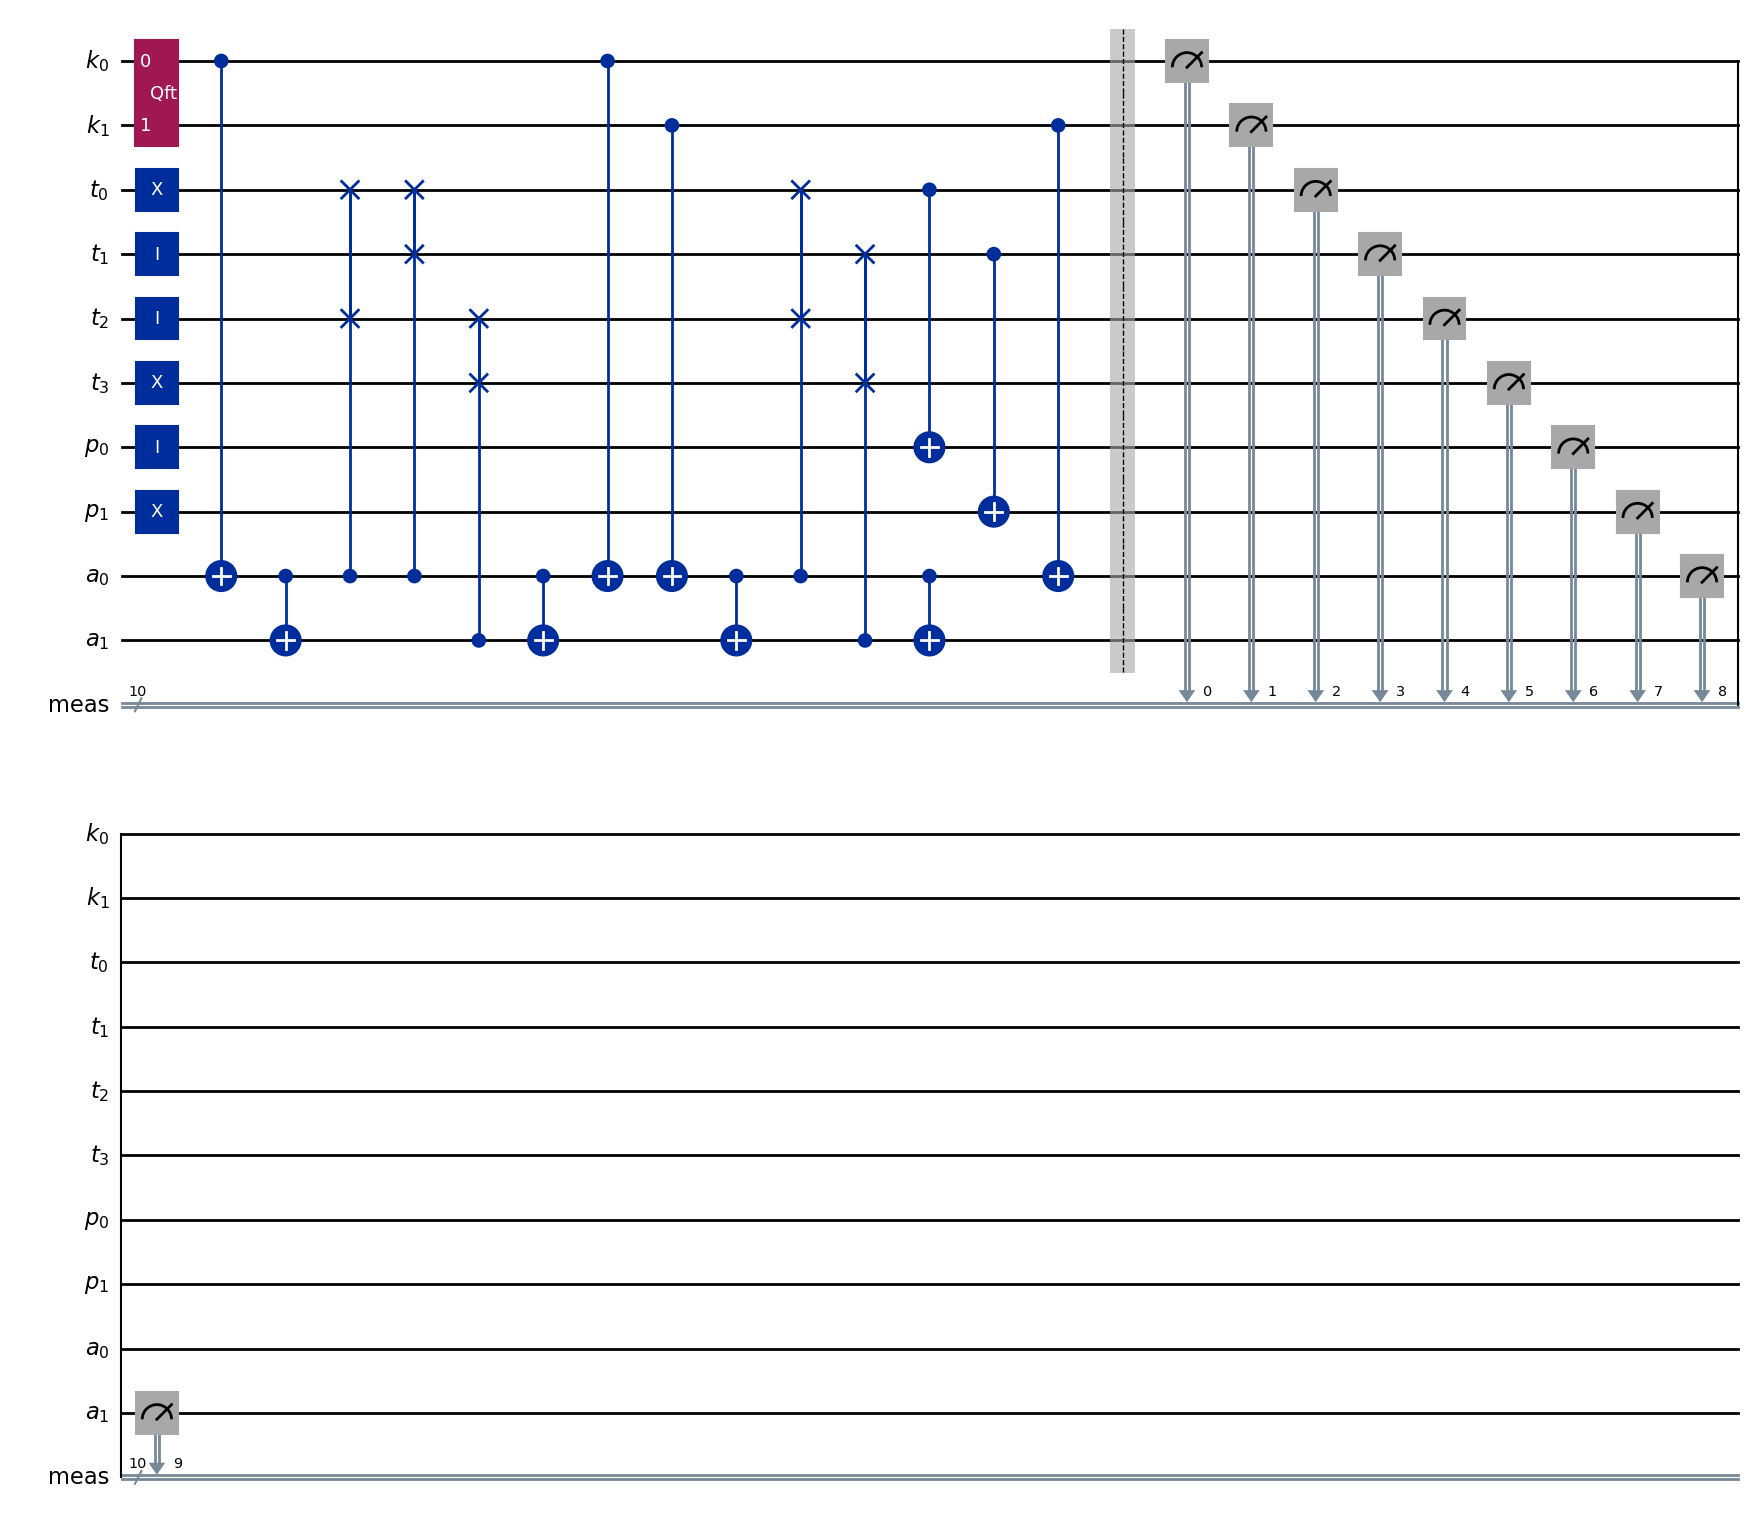

In [23]:
# 1. Inizializzazione dei registri

# Otteniamo stringa e pattern
T = "1001"
P = "01"

# Ricaviamo lunghezza di T e P; n sono i qubit necessari per rappresentare N
N = len(T)
M = len(P)
n = int(np.ceil(np.log2(N)))

# Creiamo i registri
reg_K = QuantumRegister(n, name="k") # registro indice
reg_T = QuantumRegister(N, name="t") # registro stringa
reg_P = QuantumRegister(M, name="p") # registro pattern
reg_A = QuantumRegister(N//2, name="a") # registro ancilla

# Creiamo il circuito

qc = QuantumCircuit(reg_K, reg_T, reg_P, reg_A)

# Popoliamo i registri usando identità e bit-flip come indicato nel paper
for i in range(N):
  if T[i] == "1":
    qc.x(reg_T[i])
  elif T[i] == "0":
    qc.id(reg_T[i])
  else:
    print("Errore nella codifica della stringa T")

for i in range(M):
  if P[i] == "1":
    qc.x(reg_P[i])
  elif P[i] == "0":
    qc.id(reg_P[i])
  else:
    print("Errore nella codifica del pattern")

# 2a. Usiamo la Quantum Fourier Transform per mettere in superposizione i k
qc.append(QFTGate(n), range(n))

# 2b. Implementiamo lo shift ciclico

# Usiamo degli ancilla qubit per copiare il valore k
# e usarlo in parallelo su diversi CNOT
def copy_ancilla_tree(qc, control, reg_A):
  # primo passo: copiamo dal controllo al primo ancilla
  qc.cx(control, reg_A[0])

  copied = 1
  while copied < len(reg_A):
    for i in range(copied):
      if (i + copied) < len(reg_A):
        qc.cx(reg_A[i], reg_A[copied + i])
    copied *= 2

def reset_ancilla_tree(qc, control, reg_A):
  # Partiamo dall'ultimo livello dell'albero e torniamo indietro per pulire reg_A
  step = 1
  while step * 2 < len(reg_A):
    step *= 2

  while step >= 1:
    for i in range(step - 1, -1, -1):
      if (i + step) < len(reg_A):
        qc.cx(reg_A[i], reg_A[step + i])
    step //= 2

  qc.cx(control, reg_A[0])

# Shift ciclico
for z in range(n):
  k = 2**z
  copy_ancilla_tree(qc, reg_K[z], reg_A) # copia k in reg_A

  # i = strati paralleli, j = blocchi, x = elementi dei blocchi (prima metà)
  for i in range(int(np.log2(N)-np.log2(k)), 0, -1): # ordine inverso perché leftward
    anc_id = 0
    for j in range(N//((2**i)*k)):
      for x in range(j*k*(2**i), (j*(2**i)+1)*k):
        qc.cswap(reg_A[anc_id], reg_T[x], reg_T[x+(2**(i-1))*k])
        anc_id += 1

  reset_ancilla_tree(qc, reg_K[z], reg_A) # ripulisce reg_A per il giro dopo


# 3. Compariamo i primi M caratteri di T nei diversi cicli con P
for i in range(M):
  qc.cx(reg_T[i], reg_P[i]) # il CNOT esegue uno XOR, il risultato va nel secondo parametro


# 4. P è tutto 0 se il pattern e la sottostringa sono identici,
# altrimenti ha tanti 1 quanti i bit differenti


# 5. Isoliamo i casi di match usando l'algoritmo di Grover


qc.measure_all()
qc.draw('mpl')